# 03 · Causal discovery with PCMCI+

**Objective.** Learn a temporal causal graph of the coolant subsystem from data with PCMCI+ (Tigramite), without using the expert graph, and quantify how stable the result is.

**Method choices and why**

| Choice | Decision | Reason |
|---|---|---|
| Data | normal training recordings + coolant fault runs | fault variables are constant in normal operation (EDA), so normal data alone cannot reveal their effects |
| Regimes | one PCMCI+ run per regime: normal operation, and each fault scenario | each scenario records different variables; pooling them would turn *not recorded* into *independent* (Tigramite returns p = 1 for constant or missing data) |
| Variables per regime | recorded in every recording of the regime and changing at least once | a constant variable carries no information about dependence |
| CI test | G² test for discrete data (`Gsquared`) | all coolant variables are binary; ParCorr assumes continuous, linear-Gaussian data |
| Recordings | separate Tigramite datasets (`analysis_mode='multiple'`) | lags never cross recording boundaries |
| Grid, lags | Δ = 0.5 s (Stage 1), `tau_max` = 10 s = 20 steps | 0.5 s keeps all coolant changes and separates more of them in time; 10 s is a generic window for PLC reactions. Sensitivity: Δ = 1 s, `tau_max` 5 s and 20 s |
| Significance | `pc_alpha` = 0.01; Benjamini–Hochberg FDR on lagged links | fixed before looking at results; sensitivity 0.001 and 0.05. Tigramite 5.2's PCMCI+ decides and orients every link with uncorrected tests at 0.01, then BH-corrects only the *reported* p-values of lagged links (lag-0 p-values stay uncorrected). Lagged links whose corrected p-value exceeds 0.01 are therefore removed afterwards. The uncorrected graph is a sensitivity variant |
| Conditioning sets | at most 3 conditions, at most 3 lagged parents of X and of Y in MCI tests | larger binary contingency tables are empty and the test loses validity |
| Combining regimes | a relation is kept when found in ≥ 50% of the regimes where its pair was testable | evidence is only counted where it could exist |

**Contemporaneous links.** Most events share timestamps with other events (EDA), so lag-0 links are not oriented by time. PCMCI+ orients some of them through conditional-independence rules (`-->`); the others stay unoriented (`o-o`) and are reported as undirected, never oriented by guesswork.

**No expert graph here.** The expert graph is not used for discovery, `tau_max`, `pc_alpha` or any other choice in this notebook. The comparison happens in notebook 04.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from causal_rca import causal_discovery as cd
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import preprocessing as pp

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)

SUBSYSTEM = 'coolant'
PRIMARY = cd.DiscoveryConfig(interval_s=0.5, tau_max_s=10.0, pc_alpha=0.01)
N_BOOT = 20
SEED = 0
print(PRIMARY.to_dict())

{'interval_s': 0.5, 'tau_max_s': 10.0, 'pc_alpha': 0.01, 'fdr_method': 'fdr_bh', 'max_conds_dim': 3, 'max_conds_px': 3, 'max_conds_py': 3, 'apply_fdr_to_graph': True, 'support_threshold': 0.5, 'tau_max': 20, 'label': 'dt0.5_tau10s_alpha0.01'}


In [2]:
# model-ready matrices and splits from notebook 02
view_data = {dt: pp.load_view_data(data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{dt:g}')[0] for dt in (0.5, 1.0)}
splits = pd.read_csv(data.RESULTS_DIR / 'tables' / f'02_{SUBSYSTEM}_splits.csv')
NODES = sorted(view_data[0.5].var_names)
regimes = cd.define_regimes(splits)
types = {n: ('Alarm' if '_A_' in n else 'Binary') for n in NODES}
print({r: len(ids) for r, ids in regimes.items()})

{'normal': 119, 'exp_22': 6, 'exp_27': 7, 'exp_28': 6, 'exp_35': 6}


## 1. Regimes and the variables each one can test

In [3]:
# variables used per regime (recorded everywhere in the regime and changing at least once)
vd = view_data[PRIMARY.interval_s]
regime_vars = {r: cd.regime_variables(vd, ids) for r, ids in regimes.items()}
regime_table = pd.DataFrame([
    {'regime': r, 'recordings': len(ids), 'samples': int(sum(len(vd.arrays[i]) for i in ids)),
     'variables used': len(regime_vars[r]), 'variables': ', '.join(regime_vars[r])}
    for r, ids in regimes.items()
])
ev.save_table(regime_table, f'03_{SUBSYSTEM}_regimes')
regime_table

,regime,recordings,samples,variables used,variables
0,normal,119,136958,3,"HP_Pump_isOff, LP_Pump_On, LT_Pump_Ok"
1,exp_22,6,3993,7,"HP_A_700304, HP_Pump_Ok, HP_Pump_isOff, LP_Pum..."
2,exp_27,7,3433,6,"CLT_A_700310, CLT_Level_lt_Min, HP_A_700304, H..."
3,exp_28,6,2874,8,"CLF_A_700307, CLF_Filter_Ok, F_A_700313, F_Fil..."
4,exp_35,6,3521,7,"CLF_A_700307, CLF_Filter_Ok, HP_Pump_isOff, LP..."


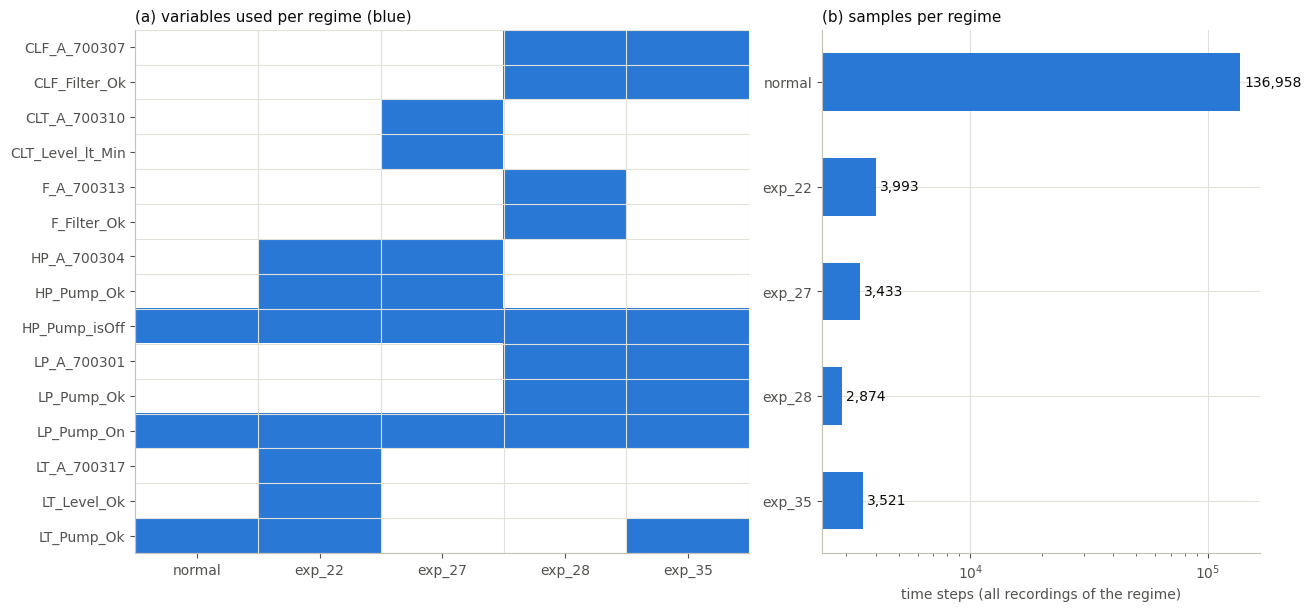

In [4]:
# figure 1: which variables each regime can use
used = np.array([[n in regime_vars[r] for r in regimes] for n in NODES], dtype=float)
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1.4, 1]}, layout='constrained')
ax_a.imshow(used, cmap=ListedColormap([ev.INK['surface'], ev.COLORS[0]]), aspect='auto', vmin=0, vmax=1)
ax_a.set_xticks(range(len(regimes)), list(regimes))
ax_a.set_yticks(range(len(NODES)), NODES)
ax_a.set_xticks(np.arange(-0.5, len(regimes)), minor=True)
ax_a.set_yticks(np.arange(-0.5, len(NODES)), minor=True)
ax_a.grid(False)
ax_a.grid(which='minor', color=ev.INK['grid'])
ax_a.tick_params(which='minor', length=0)
ax_a.set_title('(a) variables used per regime (blue)')

bars = ax_b.barh(regime_table.regime, regime_table.samples, color=ev.COLORS[0], height=0.55)
ax_b.bar_label(bars, labels=[f'{s:,}' for s in regime_table.samples], padding=3)
ax_b.invert_yaxis()
ax_b.set_xscale('log')
ax_b.set_xlabel('time steps (all recordings of the regime)')
ax_b.set_title('(b) samples per regime')
ev.save_figure(fig, f'03_{SUBSYSTEM}_regimes')
plt.show()

In [5]:
# how many state changes the g² tests can learn from: changes per variable and regime
rows = []
for regime, ids in regimes.items():
    for v in regime_vars[regime]:
        j = vd.var_names.index(v)
        changes = sum(int(np.count_nonzero(np.diff(vd.arrays[r][~vd.masks[r][:, j], j]))) for r in ids)
        rows.append({'regime': regime, 'variable': v, 'changes': changes})
transitions = pd.DataFrame(rows)
ev.save_table(transitions, f'03_{SUBSYSTEM}_regime_transitions')
transitions.pivot(index='variable', columns='regime', values='changes')

regime,exp_22,exp_27,exp_28,exp_35,normal
variable,,,,,
CLF_A_700307,NaN,NaN,12.0,12.0,NaN
CLF_Filter_Ok,NaN,NaN,12.0,12.0,NaN
CLT_A_700310,NaN,14.0,NaN,NaN,NaN
CLT_Level_lt_Min,NaN,14.0,NaN,NaN,NaN
F_A_700313,NaN,NaN,12.0,NaN,NaN
F_Filter_Ok,NaN,NaN,12.0,NaN,NaN
HP_A_700304,12.0,14.0,NaN,NaN,NaN
HP_Pump_Ok,12.0,14.0,NaN,NaN,NaN
HP_Pump_isOff,12.0,14.0,12.0,12.0,259.0


**The G² test and these data.** All variables used here are binary (alarms included), which is what G² assumes. Continuous variables never reach this notebook (the coolant view is discrete). But two assumptions are only approximately met:
- **Few informative events.** In each fault regime every variable changes only about 12–14 times in 3,000–4,000 samples (table above). The test's χ² approximation is asymptotic, and sparse contingency cells make the p-values approximate.
- **Persistence.** States hold for many steps. PCMCI+ conditions every test on the strongest lagged parents of X and Y, including their own past, which absorbs most of this autocorrelation, but not all.

The p-values are therefore treated as a **ranking device for an exploratory graph**, not as exact error rates. The bootstrap over recordings (section 5) is the more honest measure of how reliable an edge is.

## 2. PCMCI+ per regime (primary configuration)

In [6]:
# run pcmci+ on every regime
start = time.perf_counter()
primary = cd.discover(vd, regimes, PRIMARY)
print(f'total runtime {time.perf_counter() - start:.1f} s')
runtime = pd.DataFrame([{'regime': r, 'variables': len(res.variables), 'samples': res.n_samples,
                         'runtime_s': round(res.runtime_s, 2)} for r, res in primary.results.items()])
runtime

total runtime 30.7 s


,regime,variables,samples,runtime_s
0,normal,3,136958,19.93
1,exp_22,7,3993,3.01
2,exp_27,6,3433,1.93
3,exp_28,8,2874,3.18
4,exp_35,7,3521,2.57


In [7]:
# lag-specific links (autodependencies left out of the display, kept in the saved table)
# significant = fdr-corrected p-value <= pc_alpha; only significant links enter the graph
links = primary.links
ev.save_table(links, f'03_{SUBSYSTEM}_links')
links[links.kind != 'auto'].sort_values(['regime', 'source', 'target', 'lag'])

,regime,source,target,lag,link,kind,p_value,p_corrected,g_stat,significant
29,exp_22,HP_A_700304,LT_A_700317,0,o-o,contemporaneous,5.055666e-14,False,56.708031,True
28,exp_22,HP_Pump_Ok,HP_A_700304,0,-->,contemporaneous,5.920712e-12,False,47.355653,True
31,exp_22,HP_Pump_Ok,HP_Pump_isOff,0,o-o,contemporaneous,1.243668e-06,False,23.508443,True
32,exp_22,LP_Pump_On,HP_Pump_isOff,0,-->,contemporaneous,3.732480e-03,False,11.181365,True
36,exp_22,LT_Level_Ok,LT_Pump_Ok,0,o-o,contemporaneous,1.218322e-55,False,252.889411,True
37,exp_22,LT_Level_Ok,LT_Pump_Ok,1,-->,lagged,1.161052e-01,True,9.573194,False
38,exp_22,LT_Pump_Ok,LT_Level_Ok,1,-->,lagged,9.035441e-02,True,12.669900,False
40,exp_27,CLT_Level_lt_Min,CLT_A_700310,2,-->,lagged,2.136552e-13,True,64.659567,True
42,exp_27,CLT_Level_lt_Min,HP_Pump_isOff,1,-->,lagged,1.776959e-01,True,9.690350,False
43,exp_27,HP_Pump_Ok,HP_A_700304,0,-->,contemporaneous,2.802074e-11,False,44.310513,True


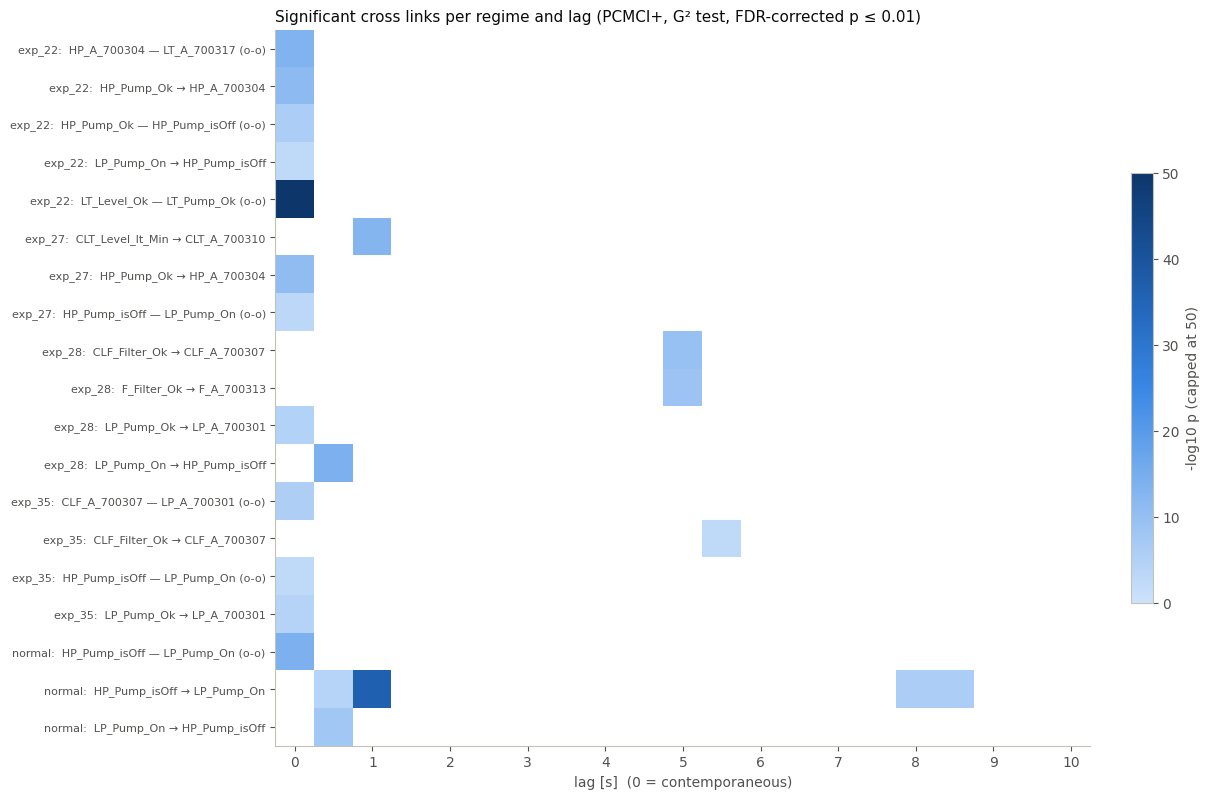

In [8]:
# figure 2: lag-specific links per regime (cross links only)
cross = links[(links.kind != 'auto') & links.significant].copy()
cross['pair'] = cross.regime + ':  ' + cross.source + ' → ' + cross.target
cross.loc[cross.link != '-->', 'pair'] = cross.regime + ':  ' + cross.source + ' — ' + cross.target + ' (' + cross.link + ')'
pairs_order = cross.sort_values(['regime', 'source', 'target']).pair.unique()
strength = np.full((len(pairs_order), PRIMARY.tau_max + 1), np.nan)
for row in cross.itertuples(index=False):
    strength[list(pairs_order).index(row.pair), row.lag] = -np.log10(max(row.p_value, 1e-300))

fig, ax = plt.subplots(figsize=(12, 0.32 * len(pairs_order) + 1.8), layout='constrained')
cmap = ev.sequential_cmap()
cmap.set_bad(ev.INK['surface'])
image = ax.imshow(np.ma.masked_invalid(np.minimum(strength, 50)), cmap=cmap, aspect='auto', vmin=0, vmax=50)
ax.set_yticks(range(len(pairs_order)), pairs_order, fontsize=8)
ax.set_xticks(range(0, PRIMARY.tau_max + 1, 2), [f'{k * PRIMARY.interval_s:g}' for k in range(0, PRIMARY.tau_max + 1, 2)])
ax.set_xlabel('lag [s]  (0 = contemporaneous)')
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.6, label='-log10 p (capped at 50)')
ax.set_title('Significant cross links per regime and lag (PCMCI+, G² test, FDR-corrected p ≤ 0.01)')
ev.save_figure(fig, f'03_{SUBSYSTEM}_lag_links')
plt.show()

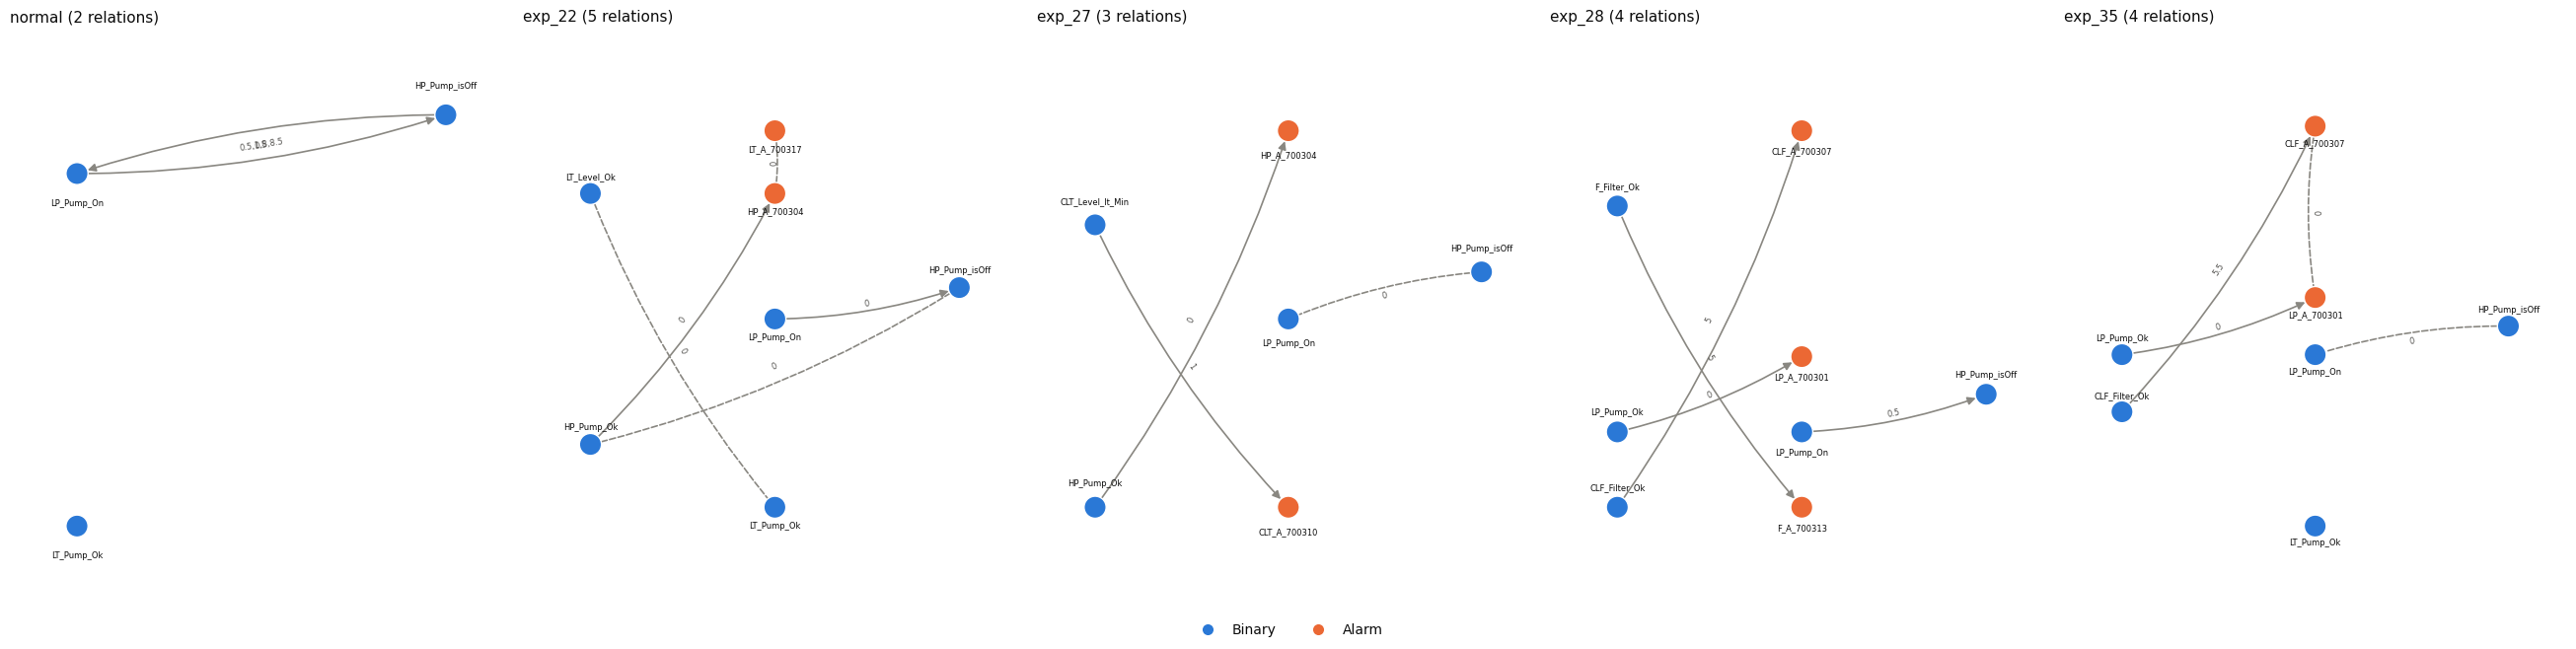

In [9]:
# figure 3: static graph of every regime (dashed = unoriented lag-0 link; labels = lags in s)
layout = ev.graph_layout(data.load_expert_graph(subsystem=SUBSYSTEM))
regime_names = list(primary.results)
fig, axes = plt.subplots(1, len(regime_names), figsize=(5.2 * len(regime_names), 6.5), layout='constrained')
for ax, regime in zip(np.atleast_1d(axes), regime_names):
    rel = primary.relations[primary.relations.regime == regime]
    g = nx.DiGraph()
    g.add_nodes_from(primary.results[regime].variables)
    for row in rel.itertuples(index=False):
        g.add_edge(row.a, row.b, oriented=row.relation == 'directed')
    ev.draw_graph(g, ax, node_types=types, title=f'{regime} ({g.number_of_edges()} relations)', pos=layout, node_size=260, font_size=6)
    labels = {(row.a, row.b): ','.join(f'{l * PRIMARY.interval_s:g}' for l in row.lags) for row in rel.itertuples(index=False)}
    nx.draw_networkx_edge_labels(g, layout, edge_labels=labels, ax=ax, font_size=6, font_color=ev.INK['secondary'],
                                 bbox={'alpha': 0})
fig.legend(handles=ev.type_legend_handles(['Binary', 'Alarm']), loc='outside lower center', ncol=2)
ev.save_figure(fig, f'03_{SUBSYSTEM}_regime_graphs')
plt.show()

## 3. Combining the regimes into one static graph

For every pair of variables we count the regimes in which the pair was **testable** (both variables used) and the regimes in which a relation was found. Lagged links are oriented by time. Lag-0 links count as directed only when PCMCI+ oriented them. A relation is kept when its support is at least 50%.

In [10]:
# pair-level support over all regimes
pairs = primary.pairs(NODES)
ev.save_table(pairs, f'03_{SUBSYSTEM}_pairs')
print(pairs.decision.value_counts().to_string())
pairs[pairs.decision.isin(['a -> b', 'b -> a', 'both directions', 'undirected'])]

decision
absent        51
untestable    44
b -> a         6
undirected     4


,a,b,n_testable,n_adjacent,n_a_to_b,n_b_to_a,support,support_a_to_b,support_b_to_a,orientation_conflict,mixed_marks,lags,regimes,decision
0,CLF_A_700307,CLF_Filter_Ok,2,2,0,2,1.0,0.0,1.0,False,False,"[10, 11]","[exp_28, exp_35]",b -> a
8,CLF_A_700307,LP_A_700301,2,1,0,0,0.5,0.0,0.0,False,False,[0],[exp_35],undirected
27,CLT_A_700310,CLT_Level_lt_Min,1,1,0,1,1.0,0.0,1.0,False,False,[2],[exp_27],b -> a
50,F_A_700313,F_Filter_Ok,1,1,0,1,1.0,0.0,1.0,False,False,[10],[exp_28],b -> a
69,HP_A_700304,HP_Pump_Ok,2,2,0,2,1.0,0.0,1.0,False,False,[0],"[exp_22, exp_27]",b -> a
74,HP_A_700304,LT_A_700317,1,1,0,0,1.0,0.0,0.0,False,False,[0],[exp_22],undirected
77,HP_Pump_Ok,HP_Pump_isOff,2,1,0,0,0.5,0.0,0.0,False,False,[0],[exp_22],undirected
86,HP_Pump_isOff,LP_Pump_On,5,5,1,3,1.0,0.2,0.6,True,True,"[0, 1, 2, 16, 17]","[exp_22, exp_27, exp_28, exp_35, normal]",b -> a
90,LP_A_700301,LP_Pump_Ok,2,2,0,2,1.0,0.0,1.0,False,False,[0],"[exp_28, exp_35]",b -> a
104,LT_Level_Ok,LT_Pump_Ok,1,1,0,0,1.0,0.0,0.0,False,False,[0],[exp_22],undirected


In [11]:
# conflicting evidence across regimes (kept and reported, not hidden by the aggregation)
conflicts = pairs[pairs.orientation_conflict | pairs.mixed_marks]
print(f'pairs found in opposite directions in different regimes: {int(pairs.orientation_conflict.sum())}')
print(f'pairs found directed in some regimes and undirected in others: {int(pairs.mixed_marks.sum())}')
conflicts[['a', 'b', 'n_testable', 'n_adjacent', 'n_a_to_b', 'n_b_to_a', 'regimes', 'decision']]

pairs found in opposite directions in different regimes: 1
pairs found directed in some regimes and undirected in others: 1


,a,b,n_testable,n_adjacent,n_a_to_b,n_b_to_a,regimes,decision
86,HP_Pump_isOff,LP_Pump_On,5,5,1,3,"[exp_22, exp_27, exp_28, exp_35, normal]",b -> a


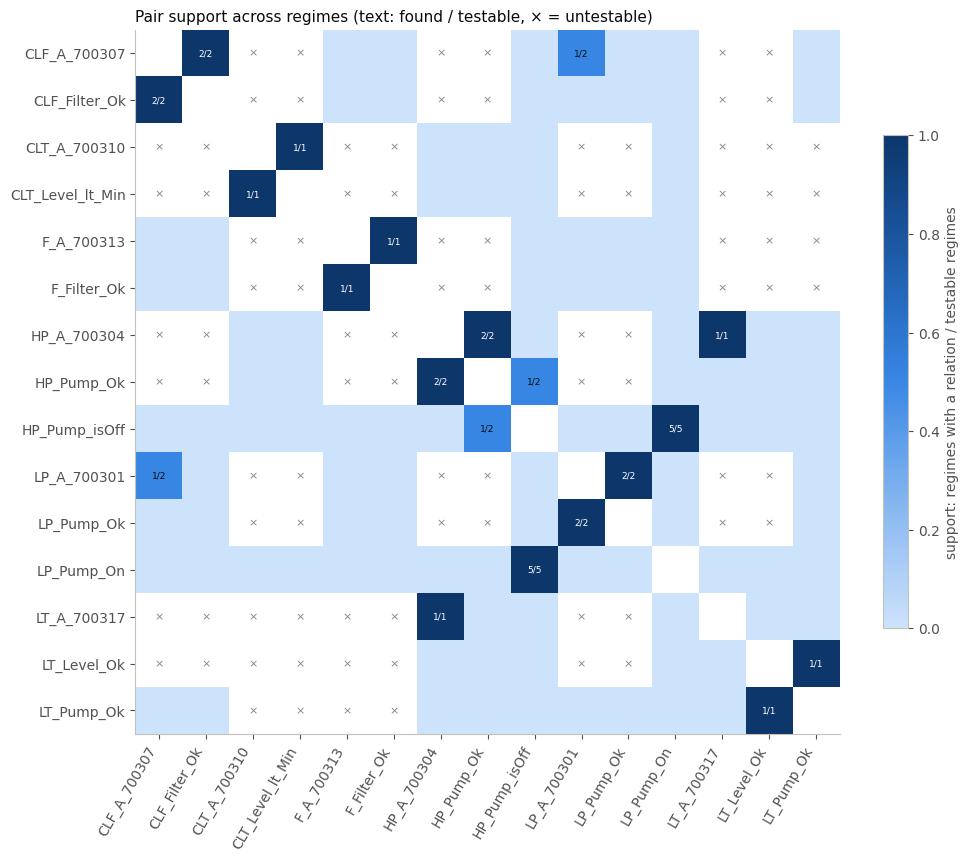

44 of 105 pairs are untestable in every regime


In [12]:
# figure 4: support of every variable pair (× = never testable)
support = pd.DataFrame(np.nan, index=NODES, columns=NODES)
for row in pairs.itertuples(index=False):
    support.loc[row.a, row.b] = support.loc[row.b, row.a] = row.support
untestable = pairs[pairs.decision == 'untestable']

fig, ax = plt.subplots(figsize=(10, 8.5), layout='constrained')
cmap = ev.sequential_cmap()
cmap.set_bad(ev.INK['surface'])
image = ax.imshow(np.ma.masked_invalid(support.to_numpy(dtype=float)), cmap=cmap, vmin=0, vmax=1)
for row in untestable.itertuples(index=False):
    for a, b in ((row.a, row.b), (row.b, row.a)):
        ax.text(NODES.index(b), NODES.index(a), '×', ha='center', va='center', fontsize=8, color=ev.INK['muted'])
for row in pairs[pairs.support > 0].itertuples(index=False):
    for a, b in ((row.a, row.b), (row.b, row.a)):
        ax.text(NODES.index(b), NODES.index(a), f'{row.n_adjacent}/{row.n_testable}', ha='center', va='center',
                fontsize=6.5, color=ev.INK['surface'] if row.support > 0.55 else ev.INK['primary'])
ax.set_xticks(range(len(NODES)), NODES, rotation=60, ha='right')
ax.set_yticks(range(len(NODES)), NODES)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.7, label='support: regimes with a relation / testable regimes')
ax.set_title('Pair support across regimes (text: found / testable, × = untestable)')
ev.save_figure(fig, f'03_{SUBSYSTEM}_pair_support')
plt.show()
print(f'{len(untestable)} of {len(pairs)} pairs are untestable in every regime')

In [13]:
# the discovered static graph (all regimes)
edges_full = primary.edges(NODES)
discovered = cd.edges_to_graph(edges_full, NODES)
print(f'{len(edges_full)} edges: {int(edges_full.oriented.sum())} oriented, {int((~edges_full.oriented).sum())} undirected')
edges_full

10 edges: 6 oriented, 4 undirected


,source,target,oriented,support,orientation_conflict
0,CLF_Filter_Ok,CLF_A_700307,True,1.0,False
1,CLF_A_700307,LP_A_700301,False,0.5,False
2,CLT_Level_lt_Min,CLT_A_700310,True,1.0,False
3,F_Filter_Ok,F_A_700313,True,1.0,False
4,HP_Pump_Ok,HP_A_700304,True,1.0,False
5,HP_A_700304,LT_A_700317,False,1.0,False
6,HP_Pump_Ok,HP_Pump_isOff,False,0.5,False
7,LP_Pump_On,HP_Pump_isOff,True,0.6,True
8,LP_Pump_Ok,LP_A_700301,True,1.0,False
9,LT_Level_Ok,LT_Pump_Ok,False,1.0,False


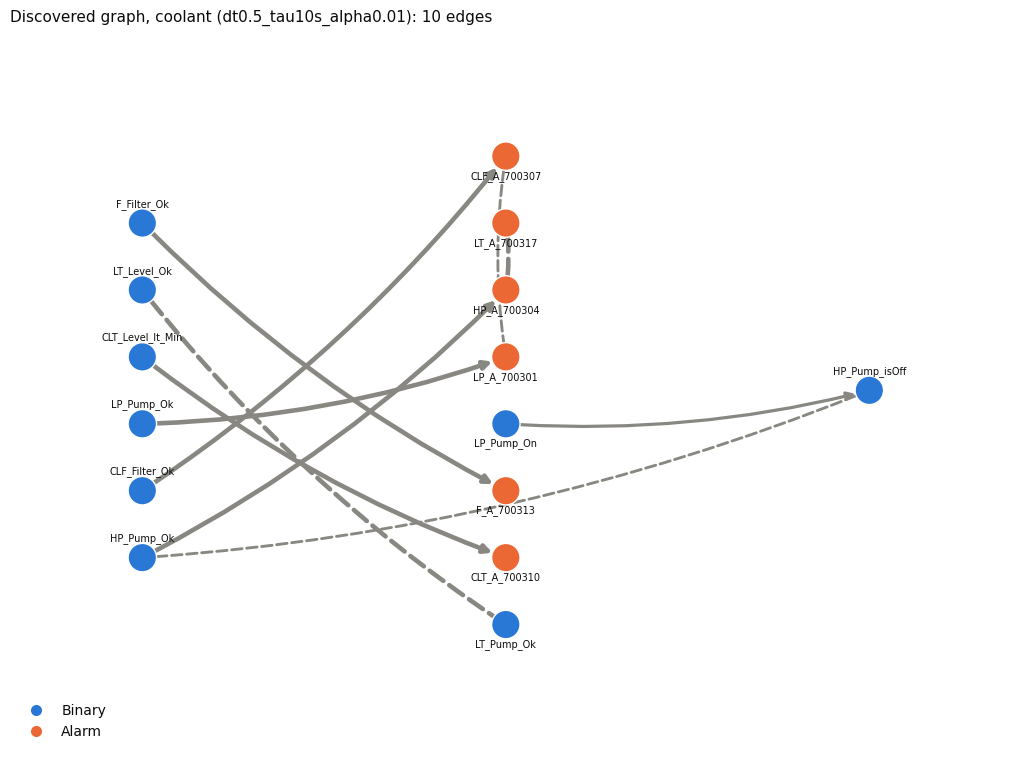

In [14]:
# figure 5: discovered static graph (width = support; dashed = undirected)
fig, ax = plt.subplots(figsize=(10, 7.5), layout='constrained')
ev.draw_graph(discovered, ax, node_types=types, pos=layout, width_by_support=True,
              title=f'Discovered graph, {SUBSYSTEM} ({PRIMARY.label}): {len(edges_full)} edges')
ax.legend(handles=ev.type_legend_handles(['Binary', 'Alarm']), loc='lower left')
ev.save_figure(fig, f'03_{SUBSYSTEM}_discovered_graph')
plt.show()

## 4. Leave-one-scenario-out graphs

Root cause analysis (notebook 06) is evaluated on one held-out fault scenario at a time. The graph it uses must not have seen that scenario, so we rebuild the graph from all regimes except the held-out one. Each regime runs only once; the folds just leave one out when combining.

In [15]:
# graphs for every leave-one-scenario-out fold, saved together with the full graph
folds = [r for r in regimes if r != 'normal']
all_edges = [edges_full.assign(graph_id='discovered')]
for fold in folds:
    all_edges.append(primary.edges(NODES, exclude=[fold]).assign(graph_id=f'discovered_without_{fold}'))
all_edges = pd.concat(all_edges, ignore_index=True)
ev.save_table(all_edges, f'03_{SUBSYSTEM}_edges')

edge_names = lambda e: [f'{s} → {t}' if o else f'{min(s, t)} — {max(s, t)}' for s, t, o in zip(e.source, e.target, e.oriented)]
all_edges['edge'] = edge_names(all_edges)
presence = all_edges.pivot_table(index='edge', columns='graph_id', values='support', aggfunc='max')
presence = presence.reindex(columns=['discovered'] + [f'discovered_without_{f}' for f in folds])
presence

graph_id,discovered,discovered_without_exp_22,discovered_without_exp_27,discovered_without_exp_28,discovered_without_exp_35
edge,,,,,
CLF_A_700307 — LP_A_700301,0.5,0.5,0.50,1.0,NaN
CLF_Filter_Ok → CLF_A_700307,1.0,1.0,1.00,1.0,1.00
CLT_Level_lt_Min → CLT_A_700310,1.0,1.0,NaN,1.0,1.00
F_Filter_Ok → F_A_700313,1.0,1.0,1.00,NaN,1.00
HP_A_700304 — LT_A_700317,1.0,NaN,1.00,1.0,1.00
HP_Pump_Ok — HP_Pump_isOff,0.5,NaN,1.00,0.5,0.50
HP_Pump_Ok → HP_A_700304,1.0,1.0,1.00,1.0,1.00
LP_Pump_Ok → LP_A_700301,1.0,1.0,1.00,1.0,1.00
LP_Pump_On → HP_Pump_isOff,0.6,0.5,0.75,0.5,0.75


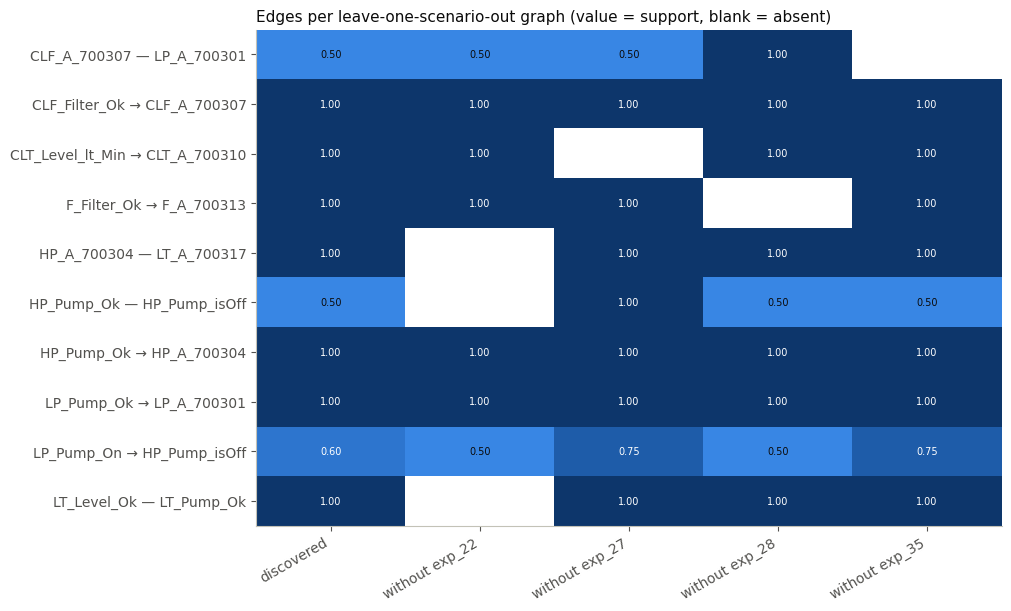

In [16]:
# figure 6: which edges survive when one scenario is left out
fig, ax = plt.subplots(figsize=(10, 0.4 * len(presence) + 2), layout='constrained')
cmap = ev.sequential_cmap()
cmap.set_bad(ev.INK['surface'])
ax.imshow(np.ma.masked_invalid(presence.to_numpy(dtype=float)), cmap=cmap, vmin=0, vmax=1, aspect='auto')
for (i, j), v in np.ndenumerate(presence.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color=ev.INK['surface'] if v > 0.55 else ev.INK['primary'])
ax.set_xticks(range(presence.shape[1]), [c.replace('discovered_without_', 'without ') for c in presence.columns], rotation=30, ha='right')
ax.set_yticks(range(len(presence)), presence.index)
ax.grid(False)
ax.set_title('Edges per leave-one-scenario-out graph (value = support, blank = absent)')
ev.save_figure(fig, f'03_{SUBSYSTEM}_loso_edges')
plt.show()

## 5. Stability: bootstrap over recordings

Recordings inside every regime are resampled with replacement and discovery is repeated. An edge's bootstrap frequency is the share of draws whose combined graph contains it.

In [17]:
# bootstrap over recordings within every regime
start = time.perf_counter()
boot = cd.bootstrap_edges(vd, regimes, PRIMARY, NODES, n_boot=N_BOOT, seed=SEED)
print(f'{N_BOOT} bootstrap draws in {time.perf_counter() - start:.0f} s')
boot['edge'] = edge_names(boot)
frequency = (boot.groupby('edge').draw.nunique() / N_BOOT).rename('bootstrap_frequency')
stability = pd.DataFrame({'in_primary_graph': frequency.index.isin(edge_names(edges_full))}, index=frequency.index)
stability['bootstrap_frequency'] = frequency
stability = stability.sort_values('bootstrap_frequency', ascending=False)
ev.save_table(stability.reset_index(), f'03_{SUBSYSTEM}_bootstrap_stability')
stability

20 bootstrap draws in 625 s


,in_primary_graph,bootstrap_frequency
edge,,
HP_A_700304 — LT_A_700317,True,1.00
CLF_Filter_Ok → CLF_A_700307,True,1.00
F_Filter_Ok → F_A_700313,True,1.00
CLT_Level_lt_Min → CLT_A_700310,True,1.00
LP_Pump_On → HP_Pump_isOff,True,0.95
LP_Pump_Ok → LP_A_700301,True,0.95
HP_Pump_Ok → HP_A_700304,True,0.95
HP_Pump_Ok — HP_Pump_isOff,True,0.80
CLF_A_700307 → LP_A_700301,False,0.60


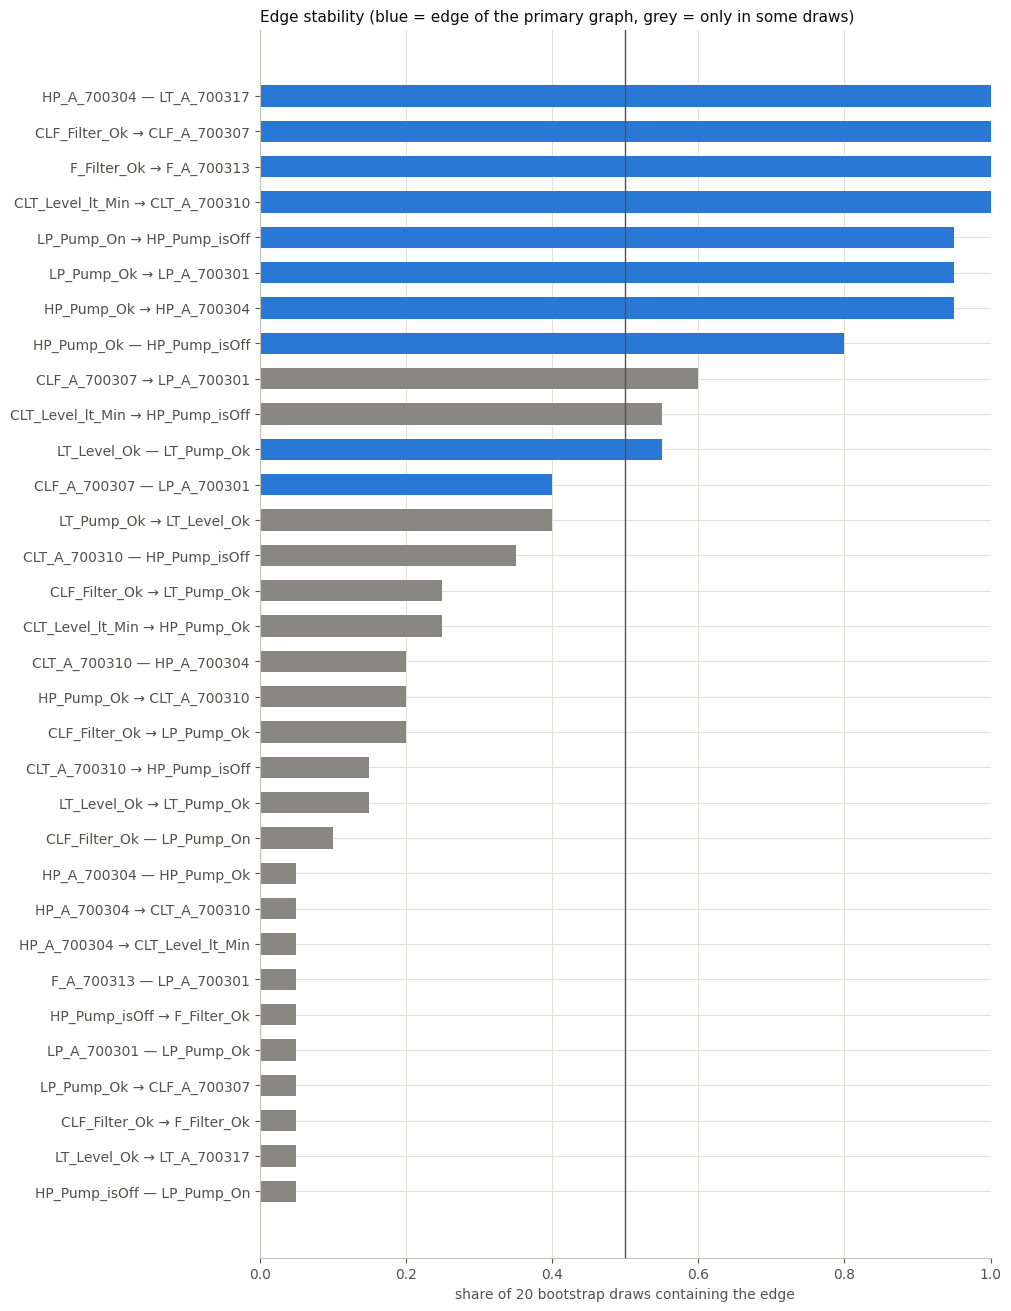

In [18]:
# figure 7: bootstrap frequency of every edge that appeared at least once
fig, ax = plt.subplots(figsize=(10, 0.35 * len(stability) + 1.8), layout='constrained')
colors = [ev.COLORS[0] if inside else ev.INK['muted'] for inside in stability.in_primary_graph]
ax.barh(stability.index, stability.bootstrap_frequency, color=colors, height=0.6)
ax.axvline(0.5, color=ev.INK['secondary'], linewidth=1)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel(f'share of {N_BOOT} bootstrap draws containing the edge')
ax.set_title('Edge stability (blue = edge of the primary graph, grey = only in some draws)')
ev.save_figure(fig, f'03_{SUBSYSTEM}_bootstrap_stability')
plt.show()

## 6. Sensitivity to the settings

One setting is changed at a time. The comparison is with the primary graph (Jaccard similarity of edge sets), **not** with the expert graph, so these runs cannot tune the result towards the reference.

In [19]:
# one-at-a-time variations of the primary configuration
variants = {
    'primary': PRIMARY,
    'grid 1 s': cd.DiscoveryConfig(interval_s=1.0, tau_max_s=10.0, pc_alpha=0.01),
    'tau_max 5 s': cd.DiscoveryConfig(interval_s=0.5, tau_max_s=5.0, pc_alpha=0.01),
    'tau_max 20 s': cd.DiscoveryConfig(interval_s=0.5, tau_max_s=20.0, pc_alpha=0.01),
    'alpha 0.001': cd.DiscoveryConfig(interval_s=0.5, tau_max_s=10.0, pc_alpha=0.001),
    'alpha 0.05': cd.DiscoveryConfig(interval_s=0.5, tau_max_s=10.0, pc_alpha=0.05),
    'no fdr filter': cd.DiscoveryConfig(interval_s=0.5, tau_max_s=10.0, pc_alpha=0.01, apply_fdr_to_graph=False),
}
variant_edges, sensitivity_rows = {}, []
primary_keys = cd.edge_key(edges_full)
for name, config in variants.items():
    start = time.perf_counter()
    result = primary if name == 'primary' else cd.discover(view_data[config.interval_s], regimes, config)
    elapsed = time.perf_counter() - start
    edges = result.edges(NODES)
    variant_edges[name] = edges.assign(variant=name)
    sensitivity_rows.append({'variant': name, **config.to_dict(), 'edges': len(edges), 'oriented': int(edges.oriented.sum()),
                             'jaccard_with_primary': cd.jaccard(cd.edge_key(edges), primary_keys),
                             'runtime_s': round(sum(r.runtime_s for r in result.results.values()), 1)})
# aggregation thresholds need no new runs
for threshold in (0.25, 0.75, 1.0):
    edges = cd.static_edges(cd.aggregate_relations(primary.relations, primary.variables_by_regime, NODES, threshold=threshold))
    name = f'support ≥ {threshold:g}'
    variant_edges[name] = edges.assign(variant=name)
    sensitivity_rows.append({'variant': name, **PRIMARY.to_dict(), 'support_threshold': threshold, 'edges': len(edges),
                             'oriented': int(edges.oriented.sum()),
                             'jaccard_with_primary': cd.jaccard(cd.edge_key(edges), primary_keys), 'runtime_s': 0.0})
sensitivity = pd.DataFrame(sensitivity_rows)
ev.save_table(sensitivity, f'03_{SUBSYSTEM}_sensitivity')
ev.save_table(pd.concat(variant_edges.values(), ignore_index=True), f'03_{SUBSYSTEM}_sensitivity_edges')
sensitivity[['variant', 'interval_s', 'tau_max_s', 'pc_alpha', 'support_threshold', 'edges', 'oriented', 'jaccard_with_primary', 'runtime_s']]

,variant,interval_s,tau_max_s,pc_alpha,support_threshold,edges,oriented,jaccard_with_primary,runtime_s
0,primary,0.5,10.0,0.010,0.50,10,6,1.000000,30.6
1,grid 1 s,1.0,10.0,0.010,0.50,13,10,0.533333,10.1
2,tau_max 5 s,0.5,5.0,0.010,0.50,10,6,1.000000,14.1
3,tau_max 20 s,0.5,20.0,0.010,0.50,10,7,0.818182,55.8
4,alpha 0.001,0.5,10.0,0.001,0.50,9,5,0.900000,25.7
5,alpha 0.05,0.5,10.0,0.050,0.50,13,5,0.642857,33.2
6,no fdr filter,0.5,10.0,0.010,0.50,13,10,0.642857,29.6
7,support ≥ 0.25,0.5,10.0,0.010,0.25,10,6,1.000000,0.0
8,support ≥ 0.75,0.5,10.0,0.010,0.75,8,5,0.636364,0.0
9,support ≥ 1,0.5,10.0,0.010,1.00,8,5,0.636364,0.0


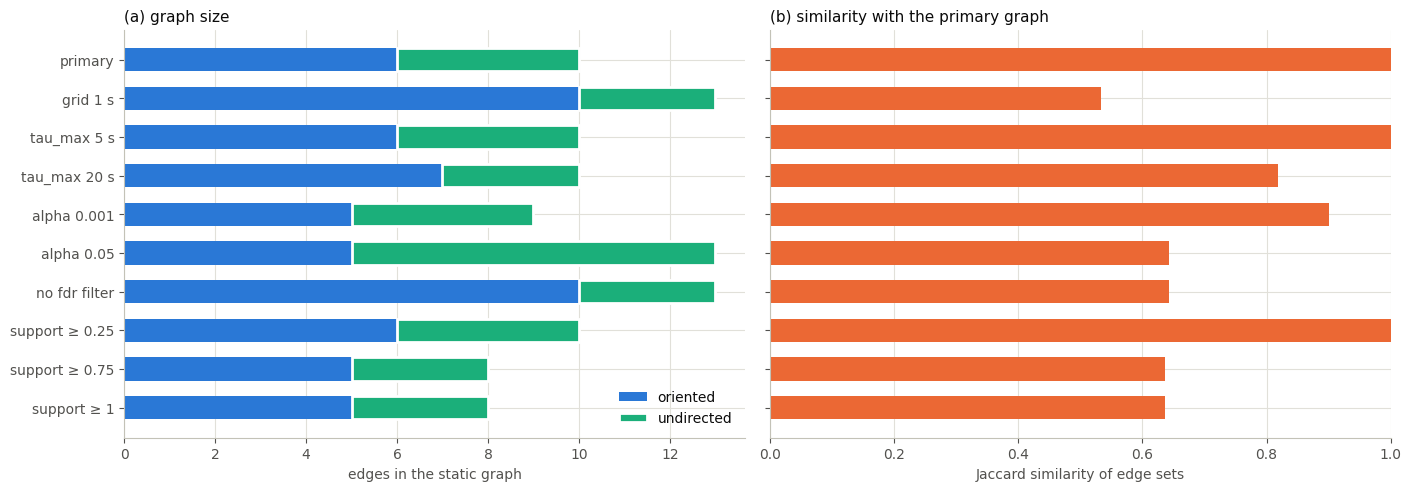

In [20]:
# figure 8: number of edges and similarity with the primary graph per variant
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True, layout='constrained')
y = np.arange(len(sensitivity))
ax_a.barh(y, sensitivity.oriented, color=ev.COLORS[0], height=0.6, label='oriented')
ax_a.barh(y, sensitivity.edges - sensitivity.oriented, left=sensitivity.oriented, color=ev.COLORS[2], height=0.6,
          label='undirected', edgecolor=ev.INK['surface'], linewidth=2)
ax_a.set_yticks(y, sensitivity.variant)
ax_a.invert_yaxis()
ax_a.set_xlabel('edges in the static graph')
ax_a.set_title('(a) graph size')
ax_a.legend(loc='lower right')
ax_b.barh(y, sensitivity.jaccard_with_primary, color=ev.COLORS[1], height=0.6)
ax_b.set_xlim(0, 1)
ax_b.set_xlabel('Jaccard similarity of edge sets')
ax_b.set_title('(b) similarity with the primary graph')
ev.save_figure(fig, f'03_{SUBSYSTEM}_sensitivity')
plt.show()

In [21]:
# save the primary configuration next to the results
(data.RESULTS_DIR / 'models').mkdir(parents=True, exist_ok=True)
(data.RESULTS_DIR / 'models' / f'03_{SUBSYSTEM}_discovery_config.json').write_text(
    json.dumps({'subsystem': SUBSYSTEM, 'primary': PRIMARY.to_dict(), 'n_boot': N_BOOT, 'seed': SEED,
                'regimes': regimes, 'variables_by_regime': primary.variables_by_regime}, indent=2))

4779

## 7. Findings

- **Runtime.** PCMCI+ needs about 30 s for all five regimes at 0.5 s; the normal regime (137k samples, 3 varying variables) takes most of it. The 20 bootstrap draws take about 10 min.
- **Per regime** (figures 2–3), each fault scenario reveals its own cause–alarm links:
  - `CLF_Filter_Ok → CLF_A_700307` and `F_Filter_Ok → F_A_700313` at a **5 s lag**. This matches the expert comment "alarm after at least 5 seconds", which was never used here.
  - `CLT_Level_lt_Min → CLT_A_700310` at 1 s.
  - `HP_Pump_Ok → HP_A_700304` and `LP_Pump_Ok → LP_A_700301` at lag 0, oriented by PCMCI+.
  - The normal regime contributes `LP_Pump_On → HP_Pump_isOff`.
- **Combined graph:** 10 edges, 6 oriented and 4 undirected. 44 of 105 pairs are untestable and 51 are tested and absent.
- **The FDR filter matters.** Without it (tigramite's default graph) the result has 13 edges (Jaccard 0.64 with the primary graph). Links whose corrected p-value exceeded 0.01 were kept there, and they also changed some orientations.
- **Stability.**
  - **7 of the 10 edges appear in ≥ 95% of the bootstrap draws.** The weakest are `LT_Level_Ok — LT_Pump_Ok` (0.55) and `CLF_A_700307 — LP_A_700301` (0.40).
  - Leaving one scenario out removes exactly the edges that only that scenario could test, e.g. `CLT_Level_lt_Min → CLT_A_700310` without exp_27 (figure 6).
- **Sensitivity** (similarity with the primary graph):
  - `tau_max` 5 s: identical graph.
  - `tau_max` 20 s: Jaccard 0.82.
  - α = 0.001: Jaccard 0.90.
  - α = 0.05: Jaccard 0.64.
  - 1 s grid: Jaccard 0.53. The 1 s grid merges more changes into lag 0, which changes which links can be oriented.
- **FDR filter check.** The filter removes 9 lagged links (corrected p 0.05–0.25); it never touches lag-0 links. PCMCI+ orients lag-0 links before the filter runs, so a removed link could in principle have supported an orientation. The only candidate is `HP_Pump_Ok → HP_A_700304` in exp_27. Re-running exp_27 with its lagged version forbidden leaves the lag-0 orientation unchanged, so the filter introduces no inconsistent orientation here.
- **Conflicting evidence.** One coolant pair is found in both directions: `HP_Pump_isOff`–`LP_Pump_On`, LP_On → isOff in 3 of 5 regimes and the reverse in 1. The normal regime shows a lagged feedback loop between the two pumps. The aggregation keeps the majority direction (support 0.6), and the conflict is reported in the table above and in the edge table (`orientation_conflict`).
- **What the graph is and is not.**
  - This is an **exploratory** graph of the dependencies that the fault excitation makes visible.
  - Each fault regime contains an external intervention (the manipulated variables are forced, with design-dependent timing), so it is not a stationary observational process. The two alarm–alarm edges are a symptom: in multi-cause scenarios the operator triggers both faults, so their alarms co-occur by experimental design.
  - Agreement with the expert graph (notebook 04) is agreement, not proof of causal identification.
- *Thesis note:*
  - Discovery is **regime-wise** by necessity: the fault runs record different variables, so a pooled run would either fail or report missing data as independence.
  - The price is that every relation rests on one or two scenarios, which is visible in the support values and the leave-one-out graphs.